# Examen Final #
- Catalina Elizondo Rodríguez
- 643153

## CASO 1 ##

In [127]:
# Tienen que estar instaladas estas
# !pip install numpy
#!pip install pandas
#%pip install scikit-learn

In [128]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error

Eres analista en una empresa inmobiliaria. Debes construir un modelo que prediga el precio (`price`) usando el dataset `Housing.csv`. Solo puedes usar Regresión Lineal o Árbol de Decisión Regressor.
Requisitos y consideraciones:
- Variables categóricas binarias ("yes"/"no"): `mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea`.
- Variable categórica multinivel: `furnishingstatus`.

Objetivo base:
1. Carga el dataset desde la URL.
2. Limpia/convierte las variables categóricas adecuadamente.
3. Separa entrenamiento y prueba (80/20, `random_state=42`).
4. Entrena ambos modelos sin definir hiperparametros solo el random_state si acaso y compara R^2 y MAE (test).
5. Justifica elección de modelo.

In [129]:
# 1. Cargamos el dataset desde la URL
url = 'https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/Housing.csv'
df = pd.read_csv(url)

# Forma del dataset y tipos de datos
print(df.shape)
print(df.dtypes)

# Verificamos que no haya nulos
print('Nulos:', df.isnull().sum().sum())

(545, 13)
price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object
Nulos: 0


In [130]:
# Contamos variables numéricas y categóricas (incluyendo el target price)
n_num = df.select_dtypes(include='number').shape[1]
n_cat = df.select_dtypes(exclude='number').shape[1]
print('Numéricas:', n_num)
print('Categóricas:', n_cat)

Numéricas: 6
Categóricas: 7


Ahora crea un split de los datos del 20% en el conjunto de test, y usando random_state=42 creando las variables X_train, X_test, y_test y y_train.

¿Cuál es el valor de shape de cada conjunto?

In [131]:
# 2. Convertimos las variables categóricas
# Variables binarias "yes"/"no" -> 1/0
binarias = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
df_modelo = df.copy()
for col in binarias:
    df_modelo[col] = df_modelo[col].map({'yes': 1, 'no': 0})

# Variable multinivel (furnishingstatus) -> variables dummy (se elimina una para no duplicar información)
df_modelo = pd.get_dummies(df_modelo, columns=['furnishingstatus'], drop_first=True, dtype=int)

df_modelo.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


In [132]:
# 3. Separamos X (variables) y y (target)
X = df_modelo.drop(columns='price')
y = df_modelo['price']

# Split 80/20 con random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(436, 13)
(109, 13)
(436,)
(109,)


In [133]:
# 4. Entrenamos ambos modelos sin hiperparámetros (sólo random_state en el árbol)
modelo_lineal = LinearRegression().fit(X_train, y_train)
modelo_arbol = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)

# Calculamos R² y MAE en el conjunto de prueba (y R² en entrenamiento para ver el sobreajuste)
resultados = []
for nombre, modelo in [('Regresión Lineal', modelo_lineal), ('Árbol de Decisión', modelo_arbol)]:
    pred = modelo.predict(X_test)
    resultados.append({
        'modelo': nombre,
        'R2_train': round(modelo.score(X_train, y_train), 3),
        'R2_test': round(r2_score(y_test, pred), 3),
        'MAE_test': round(mean_absolute_error(y_test, pred))
    })

pd.DataFrame(resultados)

,modelo,R2_train,R2_test,MAE_test
0,Regresión Lineal,0.686,0.653,970043
1,Árbol de Decisión,0.999,0.477,1195266


Cuál es el RMSE_test del Árbol de Decisión?

Valor flotante a dos decimales.

In [134]:
# R² en test de cada modelo (el de la Regresión Lineal es la respuesta de la pregunta)
r2_lineal = r2_score(y_test, modelo_lineal.predict(X_test))
r2_arbol = r2_score(y_test, modelo_arbol.predict(X_test))
print(f'R2_test Regresión Lineal: {r2_lineal:.2f}  ({r2_lineal})')
print(f'R2_test Árbol de Decisión: {r2_arbol:.2f}')

# Mejor modelo según R² en test
mejor = 'Regresión Lineal' if r2_lineal > r2_arbol else 'Árbol de Decisión'
print('Mejor modelo según R2_test:', mejor)

R2_test Regresión Lineal: 0.65  (0.6529242642153185)
R2_test Árbol de Decisión: 0.48
Mejor modelo según R2_test: Regresión Lineal


In [135]:
# RMSE del Árbol de Decisión en el conjunto de prueba
from sklearn.metrics import mean_squared_error

pred_arbol = modelo_arbol.predict(X_test)
rmse_arbol = np.sqrt(mean_squared_error(y_test, pred_arbol))
print(f'RMSE = {rmse_arbol:.2f}')

RMSE = 1625669.90


## CASO 2 ##

Este caso consiste en reproducir un flujo de clasificación para predecir si un cliente incumplirá el pago de su tarjeta de crédito comparando LogisticRegression y DecisionTreeClassifier. Cada pregunta incluye instrucciones específicas que deberás seguir en tu notebook. Las respuestas correctas se basan en los outputs obtenidos al ejecutar correctamente cada paso.


Las variables principales son:

- LIMIT_BAL: monto de crédito otorgado

- SEX: género (1 = masculino, 2 = femenino)

- EDUCATION: nivel educativo (1 = posgrado, 2 = universidad, 3 = preparatoria, otros = 0,4,5,6)

- MARRIAGE: estado civil (1 = casado, 2 = soltero, otros = 0,3)

- AGE: edad en años

- PAY_0 a PAY_6: historial de pagos (abril a septiembre 2005)

- BILL_AMT1 a BILL_AMT6: montos facturados

- PAY_AMT1 a PAY_AMT6: montos pagados

- default.payment.next.month: variable objetivo (0 = cliente que sí pagó, 1 = cliente que incumplió el pago)



Escala de PAY_0 a PAY_6 : 

-2 = No consumption, 

-1 = Paid in full, 

-0 = Hizo Pago Mínimo, 

-1 = Pago atrasado por un mes, 

- 2 = Pago atrasado por 2 meses, ... hasta 9 meses





INSTRUCCIONES GENERALES:

1. Crea un nuevo notebook en Jupyter/Colab.

2. Importa las librerías necesarias (pandas, numpy, sklearn, seaborn, matplotlib ...).

3. Carga el dataset desde el enlace proporcionado abajo.

4. Usa 'ID' como índice al leer el archivo.

5. Ejecuta cada celda en orden (de las preguntas del examen) para garantizar reproducibilidad.

6. Responde las siguientes preguntas de opción múltiple basadas en los outputs obtenidos.

Carga los datos del problema de Clasificación 'UCI Credit Card' desde la siguiente liga.
https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/UCI_Credit_Card.csv

Cambia el nombre de la columna ‘default.payment.next.month' a ‘IsDefaulter’ con la función rename de pandas. ¿Cuántos registros corresponden a la clase positiva (IsDefaulter = 1)?

In [136]:
# Installar librarias (SOLO UNA VEZ)
# %pip install seaborn matplotlib

In [137]:
# Importamos las librerías adicionales
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [138]:
# Cargamos el dataset de tarjetas de crédito usando 'ID' como índice
url_credit = 'https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/UCI_Credit_Card.csv'
df_credit = pd.read_csv(url_credit, index_col='ID')

# Forma del dataset y verificación de nulos
print(df_credit.shape)
print('Nulos:', df_credit.isnull().sum().sum())

(30000, 24)
Nulos: 0


In [139]:
# Cambiamos el nombre de la columna objetivo con rename
df_credit = df_credit.rename(columns={'default.payment.next.month': 'IsDefaulter'})

# Cuántos registros hay de cada clase (1 = incumplió el pago)
print(df_credit['IsDefaulter'].value_counts())

IsDefaulter
0    23364
1     6636
Name: count, dtype: int64


Agrupa los valores 0, 5 y 6 de la columna EDUCATION en la categoría 4 (otros).

¿Cuántos registros quedan en la categoría 4? (Es decir que cuando EDUCATION es 0, 5 ó 6 se reemplace por 4)

In [140]:
# Vemos cómo está distribuida EDUCATION antes de agrupar
print(df_credit['EDUCATION'].value_counts().sort_index())

# Agrupamos los valores 0, 5 y 6 en la categoría 4 (otros)
df_credit['EDUCATION'] = df_credit['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

# Cuántos registros hay ahora en cada categoría
print(df_credit['EDUCATION'].value_counts().sort_index())

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64


Agrupa el valor 0 de la columna MARRIAGE en la categoría 3 (otros).

¿Cuántos registros quedan en la categoría 3? (Lo mismo que en EDUCATION)

In [141]:
# Vemos cómo está distribuida MARRIAGE antes de agrupar
print(df_credit['MARRIAGE'].value_counts().sort_index())

# Agrupamos el valor 0 en la categoría 3 (otros)
df_credit['MARRIAGE'] = df_credit['MARRIAGE'].replace({0: 3})

# Cuántos registros hay ahora en cada categoría
print(df_credit['MARRIAGE'].value_counts().sort_index())

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


¿Cuál es la edad promedio de los clientes incumplidores?

Escribelo a dos decimales

In [142]:
# Edad promedio de cada grupo (0 = sí pagó, 1 = incumplió)
print(df_credit.groupby('IsDefaulter')['AGE'].mean())

# Sólo los incumplidores, a dos decimales
print(round(df_credit[df_credit['IsDefaulter'] == 1]['AGE'].mean(), 2))

IsDefaulter
0    35.417266
1    35.725738
Name: AGE, dtype: float64
35.73


Aplica One Hot Encoding, usa pd.get_dummies(), a las columnas EDUCATION y MARRIAGE

¿Cuántas variables dummies se generan en el dataset?

In [143]:
# One Hot Encoding de EDUCATION y MARRIAGE
df_dummies = pd.get_dummies(df_credit, columns=['EDUCATION', 'MARRIAGE'], dtype=int)

# Columnas dummy que se generaron
dummies = [c for c in df_dummies.columns if c.startswith('EDUCATION_') or c.startswith('MARRIAGE_')]
print(dummies)
print('Dummies generadas:', len(dummies))

['EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']
Dummies generadas: 7


Aplica One Hot Encoding, usa pd.get_dummies(drop_first=True), a las columnas PAY_0, PAY_2, PAY_3, PAY_4, PAY_5 y PAY_6.

¿Cuántas variables dummies se crean en el dataset?

In [144]:
# One Hot Encoding de las columnas PAY con drop_first=True
cols_pay = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
df_pay = pd.get_dummies(df_credit, columns=cols_pay, drop_first=True, dtype=int)

# Contamos las dummies creadas (las columnas nuevas empiezan con el nombre original + '_')
dummies_pay = [c for c in df_pay.columns if any(c.startswith(p + '_') for p in cols_pay)]
print('Dummies creadas:', len(dummies_pay))

Dummies creadas: 58


Elimina la columna 'ID' si aún existe.

¿Cuántas columnas tiene el dataframe final después de todas las transformaciones?

In [145]:
# Eliminamos la columna 'ID' si aún existe (como se cargó como índice, normalmente ya no está)
if 'ID' in df_credit.columns:
    df_credit = df_credit.drop(columns='ID')

# Aplicamos las dos codificaciones one hot al dataframe
df_final = pd.get_dummies(df_credit, columns=['EDUCATION', 'MARRIAGE'], dtype=int)
df_final = pd.get_dummies(df_final, columns=['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6'],
                          drop_first=True, dtype=int)

print('ID' in df_final.columns)
print(df_final.shape)

False
(30000, 81)


Realiza un train-test split añadiendo los siguientes parametros dentro de la función.

test_size= 0.33 
random_state = 42
stratify = df.IsDefaulter 

¿Qué resultado da len(X_train)?

In [146]:
# Separamos X (variables) y y (target)
X = df_final.drop(columns='IsDefaulter')
y = df_final['IsDefaulter']

# Train-test split estratificado por IsDefaulter
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=df_final.IsDefaulter
)

print(len(X_train))
print(len(X_test))

20100
9900


Escala los datos con StandardScaler()

Ajusta una regresión logística con los paramétros solicitados en el conjunto de entrenamiento balanceado, transformado y escalado.

C = 10
penalty = 'l2'
random_state = 42
class_weight = "balanced" 
max_iter=2000 (aumentar si es necesario)

¿Cuál es el accuracy en test redondeando a 2 decimales?

In [147]:
# Importamos el escalador y la métrica
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Escalamos: el escalador se ajusta (fit) sólo con train y se aplica a train y a test, para no tener fuga de información
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Regresión logística con los parámetros solicitados
modelo_log = LogisticRegression(C=10, penalty='l2', random_state=42, class_weight='balanced', max_iter=2000)
modelo_log.fit(X_train_sc, y_train)

# Accuracy en el conjunto de prueba
pred_log = modelo_log.predict(X_test_sc)
print('Accuracy test:', round(accuracy_score(y_test, pred_log), 2))

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Accuracy test: 0.78


¿Cuál es el recall en test del modelo de Regresión Logística?

Redondea a dos decimales.

In [148]:
from sklearn.metrics import recall_score

# Recall en test (clase positiva: IsDefaulter = 1)
print('Recall test:', round(recall_score(y_test, pred_log), 2))

Recall test: 0.57


¿Cuál es la precisión (precision) en test del modelo final?

Redondea a dos decimales

In [149]:
from sklearn.metrics import precision_score

# Precisión en test (clase positiva: IsDefaulter = 1)
print('Precision test:', round(precision_score(y_test, pred_log), 2))

Precision test: 0.49


Crea una Matriz de Confusión

Escribe aquí el código que la genera.

[[6437 1273]
 [ 951 1239]]


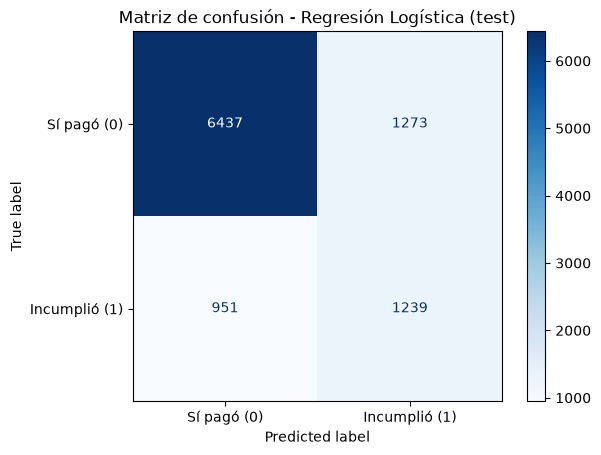

In [150]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Matriz de confusión en el conjunto de prueba
cm = confusion_matrix(y_test, pred_log)
print(cm)

# Gráfica de la matriz con etiquetas
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sí pagó (0)', 'Incumplió (1)'])
disp.plot(cmap='Blues')
plt.title('Matriz de confusión - Regresión Logística (test)')
plt.show()

Ajusta un Decision Tree Classifier con los siguientes parametros sobre los datos NO escalados, haz la inferencia y evalúa.

max_depth = 20
min_samples_split = 0.1
random_state = 42
class_weight = "balanced"

Cuál es el accuracy en test?

In [151]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Árbol de decisión con los parámetros solicitados, sobre los datos NO escalados
modelo_arbol_clf = DecisionTreeClassifier(max_depth=20, min_samples_split=0.1,
                                          random_state=42, class_weight='balanced')
modelo_arbol_clf.fit(X_train, y_train)

# Inferencia y evaluación en test
pred_arbol_clf = modelo_arbol_clf.predict(X_test)
print('Accuracy test:', round(accuracy_score(y_test, pred_arbol_clf), 2))

Accuracy test: 0.71


Accuracy : 0.71
Recall   : 0.66
Precision: 0.41
F1       : 0.51
[[5617 2093]
 [ 734 1456]]


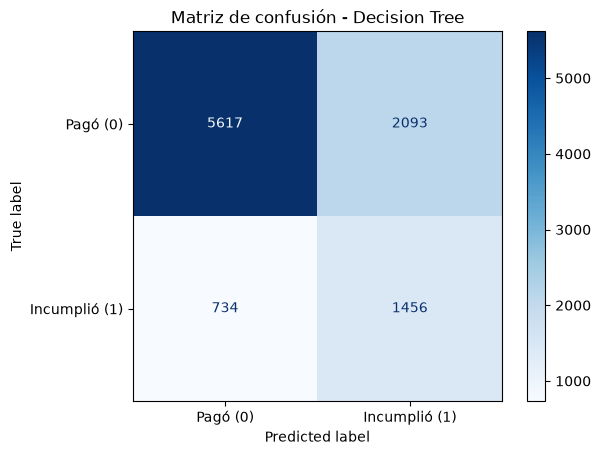

                Modelo  Accuracy  Recall  Precision    F1
0  Regresión Logística      0.78    0.57       0.49  0.53
1        Decision Tree      0.71    0.66       0.41  0.51
Mejor modelo para detectar incumplidores: Decision Tree


In [152]:
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Métricas del Árbol de Decisión en test (clase positiva: IsDefaulter = 1)
print('Accuracy :', round(accuracy_score(y_test, pred_arbol_clf), 2))
print('Recall   :', round(recall_score(y_test, pred_arbol_clf), 2))
print('Precision:', round(precision_score(y_test, pred_arbol_clf), 2))
print('F1       :', round(f1_score(y_test, pred_arbol_clf), 2))

# Matriz de confusión del árbol
cm_arbol = confusion_matrix(y_test, pred_arbol_clf)
print(cm_arbol)
ConfusionMatrixDisplay(confusion_matrix=cm_arbol, display_labels=['Pagó (0)', 'Incumplió (1)']).plot(cmap='Blues')
plt.title('Matriz de confusión - Decision Tree')
plt.show()

# Comparación de ambos modelos
comparacion = pd.DataFrame({
    'Modelo': ['Regresión Logística', 'Decision Tree'],
    'Accuracy': [accuracy_score(y_test, pred_log), accuracy_score(y_test, pred_arbol_clf)],
    'Recall': [recall_score(y_test, pred_log), recall_score(y_test, pred_arbol_clf)],
    'Precision': [precision_score(y_test, pred_log), precision_score(y_test, pred_arbol_clf)],
    'F1': [f1_score(y_test, pred_log), f1_score(y_test, pred_arbol_clf)],
}).round(2)
print(comparacion)

# Si el objetivo es detectar la mayor cantidad de incumplidores, importa el recall
mejor_modelo = comparacion.loc[comparacion['Recall'].idxmax(), 'Modelo']
print('Mejor modelo para detectar incumplidores:', mejor_modelo)

## Caso 3 ##

Segmenta universidades usando `College_Data.csv` con  K-Means o  DBSCAN.
Preguntas de opción múltiple están en celdas posteriores, sigue esas instrucciones.
Carga los datos del problema de Clustering 'College Data' desde la siguiente liga.
https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/College_Data.csv
No deben de utilizar la columna 'College'
¿Cuál es el algoritmo que se desempeña mejor con conjuntos de datos en forma de elipses?

In [153]:
# Cargamos el dataset de universidades
url_college = 'https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/College_Data.csv'
df_college = pd.read_csv(url_college)

# No se debe usar la columna 'College' (es el nombre de la universidad, no una característica)
df_college = df_college.drop(columns='College')

print(df_college.shape)
print('Nulos:', df_college.isnull().sum().sum())

(777, 18)
Nulos: 0


¿Cuál es el Silhouette Score (con random_state=42)  reportado para K-Means con K=2 y random_state=42 sin escalar los datos?

Reporta en la escala de -1 a 1, con dos decimales

In [154]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Variables numéricas (sin 'College' y sin escalar)
# 'Private' es texto (Yes/No), así que se convierte a 1/0 para poder usarla
X_college = df_college.copy()
X_college['Private'] = X_college['Private'].map({'Yes': 1, 'No': 0})

# K-Means con K=2 sobre los datos NO escalados
kmeans_2 = KMeans(n_clusters=2, random_state=42)
labels_2 = kmeans_2.fit_predict(X_college)

# Silhouette Score
print('Silhouette K=2:', round(silhouette_score(X_college, labels_2), 2))

Silhouette K=2: 0.54


Escala los datos con StandardScaler(random_state=42). Con DBSCAN eps=2.0, min_samples=5. ¿cuántos clusters se detectan? (Excluyendo el de ruido)

In [155]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# Escalamos (StandardScaler no recibe random_state)
scaler_college = StandardScaler()
X_college_sc = scaler_college.fit_transform(X_college)

# DBSCAN con eps=2.0 y min_samples=5
dbscan_college = DBSCAN(eps=2.0, min_samples=5)
labels_db = dbscan_college.fit_predict(X_college_sc)

# Clusters detectados (sin contar el ruido, que es la etiqueta -1)
n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print('Clusters:', n_clusters)
print(pd.Series(labels_db).value_counts().sort_index())

Clusters: 3
-1    289
 0    416
 1      8
 2     64
Name: count, dtype: int64


Aplica PCA con n_components=0.8 y random_state=42 a los datos escalados (tienes que crear X_pca). Después ajusta K-Means con n_clusters=3 y random_state=42 sobre X_pca.

¿Cuál es el Silhouette Score reportado?

Reporta con dos decimales en la escala de -1 a 1.

In [156]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# PCA conservando el 80% de la varianza, sobre los datos escalados
pca_college = PCA(n_components=0.8, random_state=42)
X_pca = pca_college.fit_transform(X_college_sc)
print('Componentes:', pca_college.n_components_)

# K-Means con 3 clusters sobre X_pca
kmeans_pca = KMeans(n_clusters=3, random_state=42)
labels_pca = kmeans_pca.fit_predict(X_pca)

# Silhouette Score
print('Silhouette:', round(silhouette_score(X_pca, labels_pca), 2))

Componentes: 6
Silhouette: 0.29
